# 01 · Robot, motion and sensing

The robot lives in a square 2D world and knows only two things about it:

- **What it commanded.** Each step it asks to move by `(dx, dy)`. The executed move adds noise, so the commanded motion (odometry) is only approximately what happened.
- **What it measured.** It sees landmarks inside a square window around itself and reports the offset `(Lx − x, Ly − y)` to each one, also with noise. Data association is known: every measurement carries the landmark's index.

Graph SLAM (notebook 02) takes these two noisy streams and recovers both the robot's path and the landmark map. This notebook sets up the robot model in `robot.py` and the run generator in `world.py`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable
ASSETS = Path.cwd().parent / "assets"

import matplotlib.pyplot as plt
import numpy as np

import metrics
import viz
import world
from robot import Robot

## Noise and sensing model

Both motion and measurements use **uniform** noise: each component gets an independent sample from `[-1, 1) × noise`. The sensing window is a square of half-width `measurement_range`, so a landmark is reported when both `|dx|` and `|dy|` fall inside it. Noise is added *before* the range check, which means a landmark right at the edge of the window is sometimes seen and sometimes not.

All randomness goes through a `np.random.Generator`, so every run in these notebooks is reproducible from its seed.

Robot(x=6.055, y=6.908)
landmark 0  dx=-4.238  dy=+0.899
landmark 1  dx=+1.071  dy=-3.743


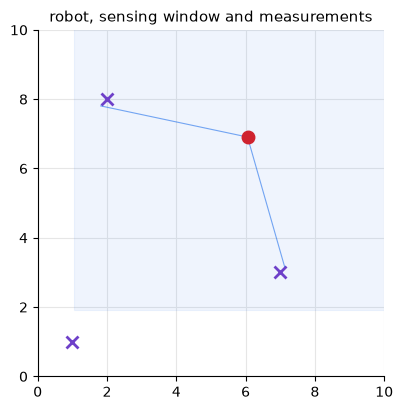

In [2]:
rng = np.random.default_rng(0)
r = Robot(world_size=10.0, measurement_range=5.0, motion_noise=0.2, measurement_noise=0.2, rng=rng)
r.landmarks = [[2.0, 8.0], [7.0, 3.0], [1.0, 1.0]]
r.move(1, 2)
print(r)

Z = r.sense()
for j, dx, dy in Z:
    print("landmark %d  dx=%+.3f  dy=%+.3f" % (j, dx, dy))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
viz.plot_world(ax, r.world_size, true_landmarks=r.landmarks, robot=r.pose,
               measurement_range=r.measurement_range, measurements=Z, legend=False,
               title="robot, sensing window and measurements")
plt.show()

Landmark 2 at (1, 1) is outside the window, so the robot reports only landmarks 0 and 1. The rays point from the robot's true position to where each measurement puts the landmark; they miss the true landmarks slightly because of the measurement noise.

The next cell repeats one measurement many times to show the noise model: the cloud of measured positions is a uniform square of side `2 × measurement_noise` centred on the true landmark, not a Gaussian blob.

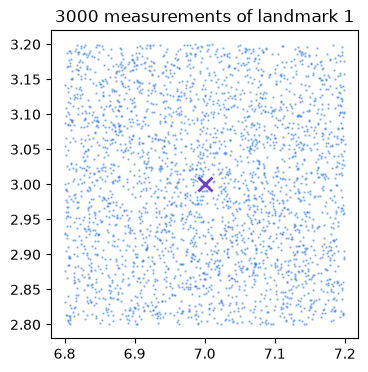

x range: 6.800 .. 7.200


In [3]:
samples = []
for _ in range(3000):
    (j, dx, dy), *_ = [m for m in r.sense() if m[0] == 1]
    samples.append((r.x + dx, r.y + dy))
samples = np.array(samples)

fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(samples[:, 0], samples[:, 1], ".", ms=1.5, alpha=0.4, color=viz.EST)
ax.plot(*r.landmarks[1], "x", color=viz.LM_TRUE, ms=10, mew=2)
ax.set_aspect("equal")
ax.set_title("3000 measurements of landmark 1")
plt.show()
print("x range: %.3f .. %.3f" % (samples[:, 0].min(), samples[:, 0].max()))

## A full run

`world.simulate_random` generates a run the same way as the original course generator. Landmarks are placed at random integer positions. The robot drives in a straight line of length `distance` per step and picks a new random heading whenever the next move would leave the world. A run is retried until every landmark has been seen at least once, because an unseen landmark has no constraints and makes the system unsolvable.

Each step of `sim.data` is `[measurements, [dx, dy]]`: what the robot saw at pose *i*, and the move that took it to pose *i + 1*. `N` poses therefore give `N − 1` steps. Unlike the original generator, `simulate_random` also returns the true poses, which is what the error metrics in the following notebooks need.

In [4]:
sim = world.simulate_random(N=20, num_landmarks=5, world_size=100.0, measurement_range=50.0,
                            motion_noise=2.0, measurement_noise=2.0, distance=20.0, seed=0)
measurements, motion = sim.data[0]
print("poses: %d   steps: %d   landmarks: %d" % (sim.N, len(sim.data), sim.num_landmarks))
print("step 0 measurements:", [[j, round(dx, 2), round(dy, 2)] for j, dx, dy in measurements])
print("step 0 motion:      ", [round(float(v), 2) for v in motion])

poses: 20   steps: 19   landmarks: 5
step 0 measurements: [[0, 12.01, -21.57], [1, -47.87, -47.08], [2, 29.7, 42.45], [3, 11.17, 22.2], [4, 3.69, 42.11]]
step 0 motion:       [8.04, -18.31]


## Why odometry alone is not enough

Integrating the commanded moves (*dead reckoning*) gives a path estimate without using any measurement. Every move adds an independent error that is never corrected, so the estimate wanders away from the truth like a random walk. In a single run the error can also shrink for a while when later errors happen to cancel earlier ones, as at the end of this run, but on average it grows with the number of steps (notebook 05). Measurements of fixed landmarks are what stop that drift, and combining both sources is the job of Graph SLAM.

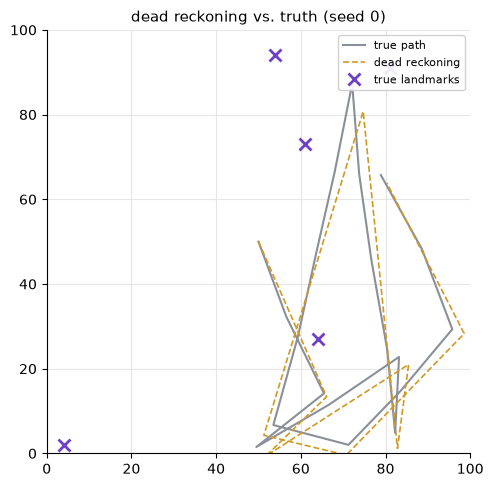

dead-reckoning error: step 5 2.88, step 10 7.03, final 2.29


In [5]:
dr = metrics.dead_reckoning(sim.data, sim.start)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
viz.plot_world(ax, sim.world_size, true_poses=sim.true_poses, dr_poses=dr,
               true_landmarks=sim.landmarks, title="dead reckoning vs. truth (seed 0)")
plt.show()

err = np.linalg.norm(dr - sim.true_poses, axis=1)
print("dead-reckoning error: step 5 %.2f, step 10 %.2f, final %.2f" % (err[5], err[10], err[-1]))